# Building-age classification: TabPFN and Random Forest ensemble

## Executive summary

**Built with PriorLabs-TabPFN.** This report tests whether a tabular foundation model can improve building-age classification in Amsterdam when only **25 labeled buildings per class (100 labels total per run)** are available.

The strongest tested procedure is a fixed probability ensemble of **25% Madrid Random Forest, 25% Amsterdam Random Forest and 50% TabPFN-v2**. It achieves **0.5842 macro F1**, compared with **0.5679** for the previous RF + fine-tuned MLP hybrid: a gain of **0.0163**, or **1.63 percentage points**. Its severe-error rate decreases from **9.53% to 8.30%**.

**Decision:** retain this fixed ensemble as the leading development candidate. The evidence comes from five spatial development folds and three matched label samples per fold; it does not establish independent competition-test performance. The tested model is the original public **TabPFN-v2**, not TabPFN-3.5.

**Reading this notebook:** saved tables and plots make the report readable without execution. Reproduction requires the accompanying repository, preprocessed data, saved baseline artifacts and checkpoint. This `.ipynb` is a complete report, not a data/model bundle.

## 1. Problem, objective and experimental question

The task is four-class building-age classification using spectral summaries from Amsterdam and Madrid. The prediction target is the ordered `age_class` (classes 1–4), not a continuous construction year. Each location is represented by **54 approved spectral features**.

Amsterdam is the target city; Madrid supplies source-city information to the existing RF model and the previous neural transfer model. The practical constraint is a small target-label budget. The question is whether TabPFN can extract more useful patterns from those same 100 Amsterdam labels, either alone or combined with the RF baseline.

**Primary objective:** improve macro F1, the equally weighted mean of the four class F1 scores. Accuracy and weighted F1 are secondary because they can favor more common classes. A severe error means a prediction at least two age classes away from the true class. Log loss and multiclass Brier score describe probability quality; smaller values are better, but neither proves calibration.

## 2. Model choices and rationale

| Procedure | Information used | Purpose |
|---|---|---|
| Original RF blend | Madrid RF + Amsterdam RF, equal probability weights | Established tree baseline |
| Previous RF + fine-tuned MLP | Existing RF–neural transfer procedure | Strongest previous development candidate |
| TabPFN-v2 | External pretrained checkpoint + 100 Amsterdam context labels | Test target-only in-context prediction |
| RF + TabPFN-v2 | Half original RF blend + half TabPFN probabilities | Test whether the two procedures complement each other |

TabPFN is pretrained on synthetic tabular tasks and conditions its predictions on a labeled training table. Here, `fit` prepares that context and fitted preprocessing; **no dataset-specific gradient updates are performed**. This differs from Madrid pretraining followed by Amsterdam fine-tuning in the previous MLP experiment.

The small context makes TabPFN a relevant candidate. The fixed ensemble tests a practical hypothesis: the RF's source/target tree predictions and TabPFN's pretrained tabular prior may make different errors. The improvement reported later supports using their combined predictions, without proving a particular causal explanation.

The experiment uses the public original v2 checkpoint and local CPU inference. It explicitly pins the checkpoint rather than relying on an alias that may resolve to different weights. Four internal inference estimators provide TabPFN's own prediction ensemble; they do not increase the target-label budget.

The new ensemble is defined before scoring:

$$P_{ensemble}=0.25P_{Madrid\ RF}+0.25P_{Amsterdam\ RF}+0.50P_{TabPFN-v2}.$$

The final class is the probability argmax. There is no outer-fold search for the mixture weight, calibration, threshold optimization or checkpoint selection.

## 3. Evaluation design and leakage controls

1. Preserve the existing **five spatial folds**, with held-out spatial groups excluded from the labeled context.
2. For each fold, reuse **three exact baseline label samples**, each containing 25 Amsterdam labels per class. This produces **15 matched TabPFN runs**.
3. Use the same approved 54 features, feature order and held-out locations as the comparison procedures. Coordinates, identifiers, years, labels and split flags are excluded from predictors.
4. Pass raw feature values, including missing entries, to TabPFN. Its fitted preprocessing uses only the permitted labeled context. Infinite values are rejected.
5. Compare against saved, verified baseline predictions on exactly aligned locations. Average the three sampling repetitions within each fold, then average the five fold means.

The new TabPFN context contains **no Madrid labels**. The RF components still use their original permitted source/target data. Thus these are comparisons of complete procedures with a matched **target-label budget**, not identical total prior information.

Fold standard deviation describes variation across these five folds; it is not a confidence interval. Repetitions share data and are not 15 independent geographic tests. These development folds have been used in earlier experiments, so model selection can be optimistic. No statistical-significance claim is made.

## 4. Environment and reproduction

Run the following from the repository root to prepare dependencies and download the exact public checkpoint:

```bash
uv sync --locked --extra tabpfn --extra deep-learning
uv run --extra tabpfn --extra deep-learning python -m scripts.download_tabpfn_checkpoint
```

The prepared Amsterdam feature table, saved baseline adaptation memberships, and `data/torch_transfer/` predictions and manifest are prerequisites. The checkpoint, labeled contexts and generated evaluation artifacts live under `data/tabpfn_experiment/` and are excluded from version control. Sending this notebook alone includes its outputs, but not those local data.

**Execution modes:** the default verifies existing evidence and reconstructs a held-out prediction probe. Set `RETRAIN = True` to run/resume the 15-context experiment; valid completed runs are reused. A new full CPU run took approximately 28 minutes. The experiment implementation remains in the accompanying script so the notebook and command-line workflow share one evaluation procedure.

The following cell locates the repository before importing project helpers. Inference uses a local checkpoint and a socket guard; no hosted prediction service or data upload is used.

In [1]:
from pathlib import Path
import os
import sys
import json

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "pyproject.toml").exists() and (p / "scripts/tabpfn_experiment.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the accompanying Building_Age_Classification repository.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "data/tabpfn_experiment/cache/matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scripts.tabpfn_experiment import (
    OUT, CONFIG, METRICS, run, verify, make_model, model_probabilities, no_network,
)

RETRAIN = False
if RETRAIN:
    run(resume=True)
verify(reload=True)
print("Verification passed: saved evidence and reconstructed held-out probabilities.")

/home/mirado/hack4dev/Building_Age_Classification/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fresh-process checkpoint + labeled-context reconstruction matches 256 held-out probabilities at the fixed query-batch shape.


Verified 60 run scores, 311,904 probability rows, 15 exact budgets, spatial exclusions and fixed blending.


Verification passed: saved evidence and reconstructed held-out probabilities.


### 4.1 Exact model and resource record

The package is pinned to **TabPFN 9.2.0**. The checkpoint is `tabpfn-v2-classifier.ckpt` from immutable revision `275f19d2add9c2c0de38f9ebaded3856599fa2e7`; SHA-256 is `f65a35685aeef42e31b796d9bfa34e68d6fc780bc98e7bff7763802964cf435f`.

The model-weight license is **Prior Labs License 1.1 (May 2025)**, retained with the checkpoint. Code and weight licenses are separate. This notebook documents local research evaluation; competition eligibility and deployment approval are separate decisions.

CPU configuration: four Torch threads, four inference estimators, cached context fitting, one preprocessing worker, query batches of 256 and no probability balancing. Seeds follow `10042 + 100 × fold + repetition`. The following records come from the completed experiment, rather than a new timing benchmark.

In [2]:
manifest = json.loads((OUT/'experiment.json').read_text())
print(CONFIG)
display(pd.Series(manifest['checkpoint']))
display(pd.Series(manifest['versions']))
print('Elapsed fit + prediction seconds:',
      manifest['total_context_fit_predict_seconds'])
print('Peak process RSS MiB:', manifest['peak_process_rss_mib'])

{'model_version': 'v2', 'n_estimators': 4, 'device': 'cpu', 'torch_threads': 4, 'fit_mode': 'fit_with_cache', 'n_preprocessing_jobs': 1, 'query_batch_size': 256, 'folds': 5, 'repetitions': 3, 'labels_per_class': 25, 'rf_weight': 0.5, 'seed_base': 10042, 'balance_probabilities': False}


repository                                Prior-Labs/TabPFN-v2-clf
revision                  275f19d2add9c2c0de38f9ebaded3856599fa2e7
filename                                 tabpfn-v2-classifier.ckpt
gated                                                        False
sha256           f65a35685aeef42e31b796d9bfa34e68d6fc780bc98e7b...
source_url       https://huggingface.co/Prior-Labs/TabPFN-v2-cl...
license_files                                        [LICENSE.txt]
dtype: object

tabpfn               9.2.0
torch           2.15.0+cpu
scikit-learn         1.9.1
numpy                2.5.4
pandas               3.1.0
dtype: str

Elapsed fit + prediction seconds: 1678.3124994339923
Peak process RSS MiB: 1136.62109375


## 5. Overall results

The table below is computed from saved run metrics and checked against the recorded fold aggregation. Macro F1 is the selection metric. Error bars show descriptive spatial-fold standard deviation. Severe errors are plotted separately because larger age mistakes matter even when macro F1 improves.

,macro_f1,macro_f1_fold_sd,weighted_f1,accuracy,balanced_accuracy,severe_error_rate,log_loss,brier
method,,,,,,,,
RF + TabPFN-v2,0.5842,0.0174,0.5931,0.5919,0.6024,0.0830,0.9841,0.5435
TabPFN-v2,0.5709,0.0171,0.5766,0.5773,0.5964,0.0925,0.9919,0.5496
Previous RF + fine-tuned MLP,0.5679,0.0158,0.5769,0.5767,0.5858,0.0953,1.0188,0.5625
Original RF blend,0.5494,0.0258,0.5636,0.5652,0.5559,0.0863,1.0552,0.5816


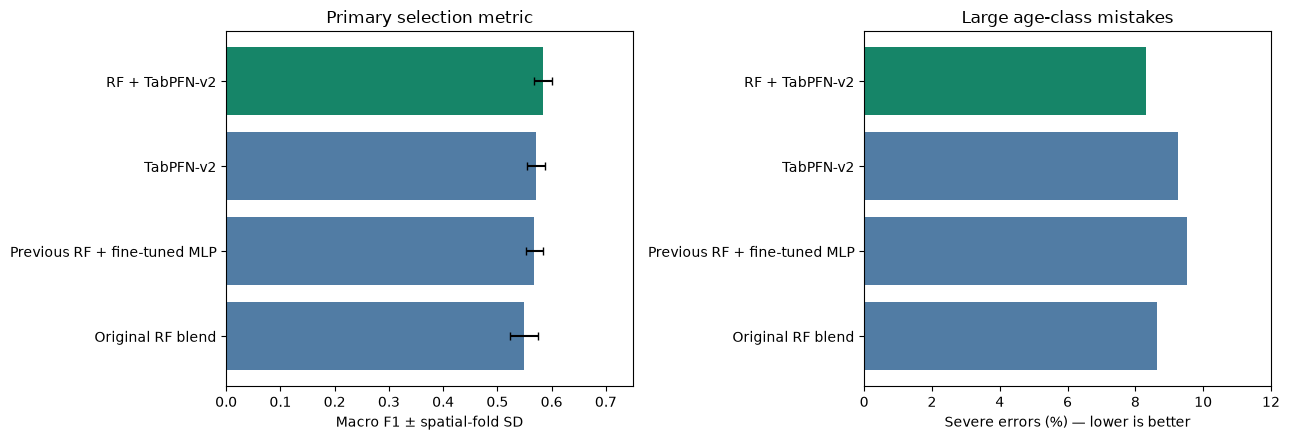

In [3]:
LABELS = {
    "original_blend": "Original RF blend",
    "rf_fine_tuned_blend": "Previous RF + fine-tuned MLP",
    "tabpfn_v2": "TabPFN-v2",
    "rf_tabpfn_v2_blend": "RF + TabPFN-v2",
}
runs = pd.read_csv(OUT / "run_metrics.csv")
folds = runs.groupby(["method", "fold"])[METRICS].mean()
summary = pd.read_csv(OUT / "summary.csv", index_col="method")
np.testing.assert_allclose(folds.groupby("method").mean(), summary[METRICS], atol=1e-12)
np.testing.assert_allclose(folds.groupby("method").macro_f1.std(), summary.macro_f1_fold_sd, atol=1e-12)
columns = ["macro_f1", "macro_f1_fold_sd", "weighted_f1", "accuracy",
           "balanced_accuracy", "severe_error_rate", "log_loss", "brier"]
display(summary[columns].sort_values("macro_f1", ascending=False).rename(index=LABELS).round(4))
ordered = summary.sort_values("macro_f1").rename(index=LABELS)
colors = ["#168568" if label == "RF + TabPFN-v2" else "#517ca4" for label in ordered.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(ordered.index, ordered.macro_f1, xerr=ordered.macro_f1_fold_sd, capsize=3, color=colors)
axes[0].set(xlabel="Macro F1 ± spatial-fold SD", xlim=(0, .75), title="Primary selection metric")
axes[1].barh(ordered.index, 100 * ordered.severe_error_rate, color=colors)
axes[1].set(xlabel="Severe errors (%) — lower is better", xlim=(0, 12), title="Large age-class mistakes")
fig.tight_layout()
fig.savefig(OUT / "comparison.png", dpi=160)
plt.show()

### Interpretation

The fixed RF + TabPFN-v2 ensemble reaches **0.5842 macro F1**. The gain is **+0.0163** over the previous RF–MLP hybrid and **+0.0348** over the original RF blend. TabPFN alone reaches **0.5709**, a smaller gain of **+0.0030** over the previous hybrid.

The combined procedure also reduces severe errors to **8.30%**, versus **9.53%** for the previous hybrid and **8.63%** for the original RF blend. Therefore the macro-F1 gain is accompanied by fewer large age-class mistakes in this development evaluation. The ensemble's stronger result than either constituent procedure supports retaining the RF contribution.

## 6. Class-level and spatial-fold checks

An overall mean can hide class or geographic regressions. The next table averages class F1 with the same repetition-then-fold rule. Classes are kept as the project's ordered labels 1–4; no unverified construction-year boundaries are introduced here.

age_class,1,2,3,4
method,,,,
Original RF blend,0.6337,0.5872,0.4847,0.4919
Previous RF + fine-tuned MLP,0.6514,0.5571,0.5437,0.5192
RF + TabPFN-v2,0.6601,0.5769,0.5633,0.5365
TabPFN-v2,0.6535,0.5340,0.5654,0.5307


,fold,Original RF blend,Previous RF + fine-tuned MLP,RF + TabPFN-v2,TabPFN-v2,tabpfn_blend_minus_current
0,0,0.53277,0.56070,0.57016,0.55902,0.00946
1,1,0.56334,0.56336,0.58804,0.57149,0.02468
2,2,0.55149,0.56196,0.59128,0.58047,0.02932
3,3,0.58276,0.59583,0.60747,0.59328,0.01165
4,4,0.51657,0.55750,0.56411,0.55015,0.00660


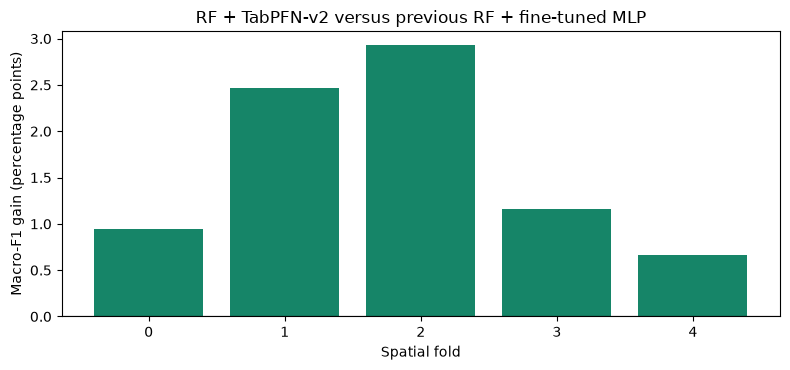

In [4]:
classes = pd.read_csv(OUT / "class_metrics.csv")
class_f1 = (classes.groupby(["method", "fold", "age_class"]).f1.mean()
            .groupby(["method", "age_class"]).mean().unstack("age_class"))
display(class_f1.rename(index=LABELS).round(4))
paired = pd.read_csv(OUT / "paired_fold_scores.csv")
display(paired.rename(columns=LABELS).round(5))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(paired["fold"].astype(str), 100 * paired["tabpfn_blend_minus_current"], color="#168568")
ax.axhline(0, color="black", linewidth=.8)
ax.set(xlabel="Spatial fold", ylabel="Macro-F1 gain (percentage points)",
       title="RF + TabPFN-v2 versus previous RF + fine-tuned MLP")
fig.tight_layout()
plt.show()

### Interpretation

The new ensemble improves all four class-level mean F1 scores relative to the previous RF + fine-tuned MLP. Its gain is positive on all five fold averages: approximately **+0.95, +2.47, +2.93, +1.16 and +0.66 percentage points**.

There is still a tradeoff: **class 2 F1 is 0.5769**, below **0.5872** for the original RF blend, even though it exceeds the previous neural hybrid's **0.5571**. The new ensemble is preferred for the macro-F1 objective; it does not dominate every baseline in every class. Five favorable fold averages are encouraging, but shared training data and repeated development use prevent treating this as proof of generalization or statistical significance.

## 7. Computational cost and verification

The recorded total context-fitting and prediction time was **1,678 seconds (28.0 minutes)** on CPU. Peak process RSS was approximately **1,137 MiB**, a process high-water mark rather than model-only memory. The timing table retains all 15 runs.

Verification recomputes **60 method/run scores from 311,904 probability rows**, checks exact label budgets, spatial exclusions, class alignment, fixed blending, fold aggregation and recorded hashes. The four method rows reuse the same held-out locations; the row count is not a count of independent buildings.

Two numerical issues were resolved transparently. First, CPU predictions differed by about 1.2e-6 between 32-row and 256-row query batches, so the reload probe now matches the evaluation's 256-row shape. Second, probability diagnostics are computed with float64 row normalization to avoid float32 rounding discrepancies; every original probability and classification score was preserved. Neither correction selected model settings by validation score.

In [5]:
timings = pd.read_csv(OUT / "timings.csv")
display(timings.round(2))
print(f"Recorded total fit + prediction: {manifest['total_context_fit_predict_seconds'] / 60:.1f} minutes")
print(f"Recorded peak process RSS: {manifest['peak_process_rss_mib']:.0f} MiB")

,fold,repetition,seed,fit_seconds,predict_seconds,n_validation,peak_process_rss_mib,actual_n_estimators,sha256
0,0,0,10042,2.28,117.80,5197,1136.62,4,566249bdfd54a0e12a5d4098473442766511820efdcf3e...
1,0,1,10043,2.34,107.66,5197,1136.62,4,90bc3681100b2416660b31d8dc643e10c811eb859b41fa...
2,0,2,10044,2.34,107.95,5197,1136.62,4,2a9bead1a35d3a1264cf4d0562774a695a8a1b39c466c4...
3,1,0,10142,2.37,111.34,5203,1136.62,4,3db9fdb021d27031657ea378d86ae2a1d05476c6a4566c...
4,1,1,10143,2.31,117.70,5203,1136.62,4,cd218f6ed813c160fda189b90ef502f072b640805955e6...
5,1,2,10144,2.28,111.18,5203,1136.62,4,15871c358d104f19375a7a1b858f07230db6fd52a1e5cb...
6,2,0,10242,2.34,107.67,5198,1136.62,4,66ac93316ca9b8b747fee83b0ab5746cef455f6561a9d4...
7,2,1,10243,2.22,113.90,5198,1136.62,4,0a9bed011abf74c38323c83bd6e4057f8f5fd0c46dc546...
8,2,2,10244,2.88,112.76,5198,1136.62,4,22d7738663b08a103ac44f6feacfc80fda2d2afe7d9b92...
9,3,0,10342,2.34,103.07,5197,1136.62,4,03a6cf859a9a04b48a087ef2dec6d27bea26f841b25462...


Recorded total fit + prediction: 28.0 minutes
Recorded peak process RSS: 1137 MiB


### 7.1 Reconstruct the checkpoint and labeled context

For TabPFN, the labeled training context is part of the inference artifact. Reproduction requires the exact checkpoint, features in the original order, context labels, seed and inference settings. The following example reconstructs fold 0 / repetition 0 and checks 256 held-out probability vectors. It is a validation example, **not a final competition model**. The displayed predictions are examples, not an additional evaluation set.

In [6]:
context = np.load(OUT/'example_context.npz', allow_pickle=False)
with no_network():
    model = make_model(CONFIG['seed_base'])
    model.fit(context['X_train'], context['y_train'])
    p = model_probabilities(model, context['X_probe'])
np.testing.assert_allclose(p, context['p_probe'], atol=1e-6)
display(pd.DataFrame(dict(location_id=context['probe_ids'], predicted_age_class=np.arange(1, 5)[p.argmax(1)],
                          **{f'p{c}': p[:, i] for i, c in enumerate(range(1, 5))})).head(8))

,location_id,predicted_age_class,p1,p2,p3,p4
0,Amsterdam:20641:193600,3,0.013292,0.043027,0.578317,0.365365
1,Amsterdam:20641:193601,3,0.050536,0.068945,0.533755,0.346765
2,Amsterdam:20641:193603,3,0.004360,0.027361,0.520819,0.447459
3,Amsterdam:20642:193600,3,0.004049,0.018418,0.499236,0.478297
4,Amsterdam:20642:193602,3,0.010102,0.039142,0.642911,0.307845
5,Amsterdam:20642:193605,4,0.001763,0.016211,0.386853,0.595173
6,Amsterdam:20642:193606,3,0.003633,0.031751,0.501093,0.463524
7,Amsterdam:20642:193610,4,0.001109,0.014399,0.177993,0.806499


## 8. Limitations and next decision

- **Development reuse:** these spatial folds informed earlier modeling work. An untouched geographic or competition evaluation is needed before claiming final performance.
- **Checkpoint scope:** only this pinned original TabPFN-v2 configuration was tested. These results say nothing about v3.5 or other TabPFN variants.
- **Prior-information differences:** the procedures share the target-label budget but differ in external pretraining and Madrid supervision. This is a practical procedure comparison, not an isolated architecture experiment.
- **Transfer and class behavior:** source/target age-label definitions remain a limitation of the source-city RF task, and class 2 remains weaker than the original RF baseline.
- **Probability and resource limits:** probabilities were not calibrated; runtime depends on hardware, batching and context size. No GPU benchmark was performed.

**Recommended next step:** freeze the existing weights and preprocessing policy, check competition rules on external pretrained models, and evaluate once on an independent geographic or competition test when available. Preserve the previous RF–MLP artifacts as a fallback. Any future weight tuning, checkpoint changes or feature selection should use a separate inner validation procedure rather than optimizing these reported outer scores.

## 9. Final conclusion

**Yes, the tested RF + TabPFN-v2 ensemble improved the development score.** It is the preferred candidate among the procedures compared here because it combines the highest macro F1 with fewer severe errors than both RF baselines.

Use the fixed **25% Madrid RF + 25% Amsterdam RF + 50% TabPFN-v2** probability blend. The following statement is calculated from the saved results so that the numerical decision remains tied to the experiment evidence.

In [7]:
best = summary.loc["rf_tabpfn_v2_blend"]
previous = summary.loc["rf_fine_tuned_blend"]
gain = best.macro_f1 - previous.macro_f1
positive_folds = int((paired["tabpfn_blend_minus_current"] > 0).sum())
display(Markdown(
    f"**Decision: retain the fixed RF + TabPFN-v2 ensemble as the leading development candidate.** "
    f"Macro F1 increases from **{previous.macro_f1:.4f}** to **{best.macro_f1:.4f}** "
    f"(**+{gain:.4f}**, or **{100 * gain:.2f} percentage points**). "
    f"Severe errors decrease from **{100 * previous.severe_error_rate:.2f}%** "
    f"to **{100 * best.severe_error_rate:.2f}%**. "
    f"The gain is positive in **{positive_folds}/5 spatial-fold averages**. "
    "This is development evidence for the pinned v2 model; independent-test performance remains unconfirmed."
))

**Decision: retain the fixed RF + TabPFN-v2 ensemble as the leading development candidate.** Macro F1 increases from **0.5679** to **0.5842** (**+0.0163**, or **1.63 percentage points**). Severe errors decrease from **9.53%** to **8.30%**. The gain is positive in **5/5 spatial-fold averages**. This is development evidence for the pinned v2 model; independent-test performance remains unconfirmed.

## 10. Sources and accompanying files

**Built with PriorLabs-TabPFN.** Model background: Hollmann et al., *Accurate predictions on small data with a tabular foundation model*, Nature 637, 319–326 (2025), [paper and DOI](https://doi.org/10.1038/s41586-024-08328-6). The paper motivates the method; the scores in this notebook come from this project's saved predictions.

- [Exact checkpoint revision](https://huggingface.co/Prior-Labs/TabPFN-v2-clf/tree/275f19d2add9c2c0de38f9ebaded3856599fa2e7) and [weight license](https://huggingface.co/Prior-Labs/TabPFN-v2-clf/blob/275f19d2add9c2c0de38f9ebaded3856599fa2e7/LICENSE.txt).
- [Official TabPFN source](https://github.com/PriorLabs/TabPFN); exact package and environment versions are recorded above.
- [Experiment implementation](../../scripts/tabpfn_experiment.py), [checkpoint downloader](../../scripts/download_tabpfn_checkpoint.py), [detailed run report](../../docs/TABPFN.md), and [exported scores](../../docs/results/tabpfn_scores.csv).

The installed TabPFN and project scikit-learn skills informed the checkpoint, leakage and reproducibility checks. Local skill resources are development tools, not competition deliverables. No skill installation is needed to read this report.

To verify or reproduce from the command line:

```bash
# Verify saved scores and hashes:
uv run --extra tabpfn --extra deep-learning python -m scripts.tabpfn_experiment --verify
# Reconstruct held-out inference in a fresh process:
uv run --extra tabpfn --extra deep-learning python -m scripts.tabpfn_experiment --reload
# Run/resume all 15 contexts (requires the prerequisite data and baseline artifacts):
uv run --extra tabpfn --extra deep-learning python -m scripts.tabpfn_experiment --resume
```